In [1]:
# ============================================================
# LOAD AND PREPARE WATER QUALITY DATA
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("../data/water_dataX.csv", encoding="latin1")

# Water-quality parameters used in the project
features = [
    'Temp',
    'D.O. (mg/l)',
    'PH',
    'CONDUCTIVITY (µmhos/cm)',
    'B.O.D. (mg/l)',
    'NITRATENAN N+ NITRITENANN (mg/l)',
    'FECAL COLIFORM (MPN/100ml)',
    'TOTAL COLIFORM (MPN/100ml)Mean'
]

# Convert parameters to numeric
for col in features:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# ------------------------------------------------------------
# REMOVE CORRUPTED pH VALUES
# ------------------------------------------------------------

invalid_ph = (df['PH'] < 0) | (df['PH'] > 14)

print("Original rows:", len(df))
print("Invalid pH rows:", invalid_ph.sum())

df = df[~invalid_ph].copy()

# Remove exact duplicate rows
df = df.drop_duplicates()

# ------------------------------------------------------------
# KEEP ONLY COMPLETE RECORDS
# ------------------------------------------------------------

model_df = df.dropna(subset=features).copy()

print("Rows after cleaning:", len(df))
print("Rows used for WQI/model:", len(model_df))

print("\nMissing values:")
print(model_df[features].isna().sum())

print("\nModel dataset shape:", model_df.shape)

print("\nFeature ranges:")
print(model_df[features].describe().T[
    ['min', '50%', 'mean', 'max']
])

# ============================================================
# model_df IS NOW READY FOR WQI CALCULATION
# ============================================================

Original rows: 1991
Invalid pH rows: 89
Rows after cleaning: 1901
Rows used for WQI/model: 1526

Missing values:
Temp                                0
D.O. (mg/l)                         0
PH                                  0
CONDUCTIVITY (µmhos/cm)             0
B.O.D. (mg/l)                       0
NITRATENAN N+ NITRITENANN (mg/l)    0
FECAL COLIFORM (MPN/100ml)          0
TOTAL COLIFORM (MPN/100ml)Mean      0
dtype: int64

Model dataset shape: (1526, 12)

Feature ranges:
                                   min     50%           mean           max
Temp                              10.0   27.00      26.273418  3.500000e+01
D.O. (mg/l)                        0.0    6.70       6.311094  1.000000e+01
PH                                 2.6    7.20       7.174868  9.010000e+00
CONDUCTIVITY (µmhos/cm)           11.0  183.00    1872.829050  4.715600e+04
B.O.D. (mg/l)                      0.1    1.80       5.311029  5.345000e+02
NITRATENAN N+ NITRITENANN (mg/l)   0.0    0.52       1.427623  5

In [2]:
# ============================================================
# FINAL WQI CALCULATION
# ============================================================

wqi_df = model_df.copy()


# ------------------------------------------------------------
# NORMALIZED WATER QUALITY RATINGS
# ------------------------------------------------------------

# pH
def calc_npH(x):
    if 7 <= x <= 8.5:
        return 100
    elif (8.5 < x <= 8.6) or (6.8 <= x < 7):
        return 80
    elif (8.6 < x <= 8.8) or (6.7 <= x < 6.8):
        return 60
    elif (8.8 < x <= 9) or (6.5 <= x < 6.7):
        return 40
    else:
        return 0


# Dissolved Oxygen
def calc_ndo(x):
    if x >= 6:
        return 100
    elif 5.1 <= x < 6:
        return 80
    elif 4.1 <= x < 5.1:
        return 60
    elif 3 <= x < 4.1:
        return 40
    else:
        return 0


# BOD
def calc_nbdo(x):
    if 0 <= x <= 3:
        return 100
    elif 3 < x <= 6:
        return 80
    elif 6 < x <= 80:
        return 60
    elif 80 < x <= 125:
        return 40
    else:
        return 0


# Conductivity
def calc_nec(x):
    if 0 <= x <= 75:
        return 100
    elif 75 < x <= 150:
        return 80
    elif 150 < x <= 225:
        return 60
    elif 225 < x <= 300:
        return 40
    else:
        return 0


# Nitrate
def calc_nna(x):
    if 0 <= x <= 20:
        return 100
    elif 20 < x <= 50:
        return 80
    elif 50 < x <= 100:
        return 60
    elif 100 < x <= 200:
        return 40
    else:
        return 0


# Total Coliform
def calc_nco(x):
    if 0 <= x <= 5:
        return 100
    elif 5 < x <= 50:
        return 80
    elif 50 < x <= 500:
        return 60
    elif 500 < x <= 1000:
        return 40
    else:
        return 0


# ------------------------------------------------------------
# APPLY RATINGS
# ------------------------------------------------------------

wqi_df["npH"] = wqi_df["PH"].apply(calc_npH)

wqi_df["ndo"] = wqi_df["D.O. (mg/l)"].apply(calc_ndo)

wqi_df["nbdo"] = wqi_df["B.O.D. (mg/l)"].apply(calc_nbdo)

wqi_df["nec"] = wqi_df[
    "CONDUCTIVITY (µmhos/cm)"
].apply(calc_nec)

wqi_df["nna"] = wqi_df[
    "NITRATENAN N+ NITRITENANN (mg/l)"
].apply(calc_nna)

wqi_df["nco"] = wqi_df[
    "TOTAL COLIFORM (MPN/100ml)Mean"
].apply(calc_nco)


# ------------------------------------------------------------
# WEIGHTS
# ------------------------------------------------------------

wqi_df["wph"] = wqi_df["npH"] * 0.165

wqi_df["wdo"] = wqi_df["ndo"] * 0.281

wqi_df["wbdo"] = wqi_df["nbdo"] * 0.234

wqi_df["wec"] = wqi_df["nec"] * 0.009

wqi_df["wna"] = wqi_df["nna"] * 0.028

wqi_df["wco"] = wqi_df["nco"] * 0.281


# ------------------------------------------------------------
# FINAL WQI
# ------------------------------------------------------------

wqi_df["WQI"] = (
    wqi_df["wph"]
    + wqi_df["wdo"]
    + wqi_df["wbdo"]
    + wqi_df["wec"]
    + wqi_df["wna"]
    + wqi_df["wco"]
)


# ============================================================
# OUTPUT
# ============================================================

print("=" * 60)
print("FINAL WQI STATISTICS")
print("=" * 60)
print(wqi_df["WQI"].describe())

print("\n" + "=" * 60)
print("WQI RANGE")
print("=" * 60)
print("Minimum:", wqi_df["WQI"].min())
print("Maximum:", wqi_df["WQI"].max())
print("Median :", wqi_df["WQI"].median())

print("\n" + "=" * 60)
print("WQI MISSING")
print("=" * 60)
print(wqi_df["WQI"].isna().sum())

print("\n" + "=" * 60)
print("FIRST 20 WQI VALUES")
print("=" * 60)

print(
    wqi_df[
        [
            "PH",
            "D.O. (mg/l)",
            "B.O.D. (mg/l)",
            "CONDUCTIVITY (µmhos/cm)",
            "NITRATENAN N+ NITRITENANN (mg/l)",
            "TOTAL COLIFORM (MPN/100ml)Mean",
            "npH",
            "ndo",
            "nbdo",
            "nec",
            "nna",
            "nco",
            "WQI"
        ]
    ].head(20).to_string(index=False)
)

print("\n" + "=" * 60)
print("WQI > 75")
print("=" * 60)
print((wqi_df["WQI"] > 75).sum())

print("\n" + "=" * 60)
print("WQI <= 75")
print("=" * 60)
print((wqi_df["WQI"] <= 75).sum())

print("\n" + "=" * 60)
print("FINAL SHAPE")
print("=" * 60)
print(wqi_df.shape)

FINAL WQI STATISTICS
count    1526.000000
mean       73.698938
std        14.147088
min        19.300000
25%        66.120000
50%        75.220000
75%        83.700000
max        98.900000
Name: WQI, dtype: float64

WQI RANGE
Minimum: 19.3
Maximum: 98.9
Median : 75.22

WQI MISSING
0

FIRST 20 WQI VALUES
 PH  D.O. (mg/l)  B.O.D. (mg/l)  CONDUCTIVITY (µmhos/cm)  NITRATENAN N+ NITRITENANN (mg/l)  TOTAL COLIFORM (MPN/100ml)Mean  npH  ndo  nbdo  nec  nna  nco   WQI
7.2          5.7            2.0                    189.0                               0.2                          8391.0  100   80   100   60  100    0 65.72
6.9          6.3            1.7                    179.0                               0.1                          5330.0   80  100   100   60  100    0 68.04
6.9          5.8            3.8                     64.0                               0.5                          8443.0   80   80    80  100  100    0 58.10
7.3          5.8            1.9                     83.

Training samples: 1220
Testing samples : 306

MODEL COMPARISON
            Model      MAE     RMSE  R2 Score
Gradient Boosting 0.645844 1.591698  0.988705
    Random Forest 0.940005 2.268287  0.977062
    Decision Tree 1.264248 3.538459  0.944181
Linear Regression 8.399144 9.890802  0.563871

BEST HYPERPARAMETERS
{'learning_rate': 0.1, 'max_depth': 3, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 150}

Best Cross-Validation R2:
0.9941298794038473

FINAL TUNED GRADIENT BOOSTING MODEL
MAE  : 0.5628406626223883
RMSE : 1.4579645497850255
R²   : 0.9905235546390294

ACTUAL VS PREDICTED
 Actual WQI  Predicted WQI
      87.66      87.532131
      51.36      56.123882
      40.30      44.626442
      71.52      71.571326
      27.10      28.644099
      70.80      70.829949
      85.08      85.161206
      88.02      87.842407
      79.64      79.625810
      94.18      94.082826
      83.70      83.592397
      83.52      83.402925
      30.54      30.729149
      87.66      8

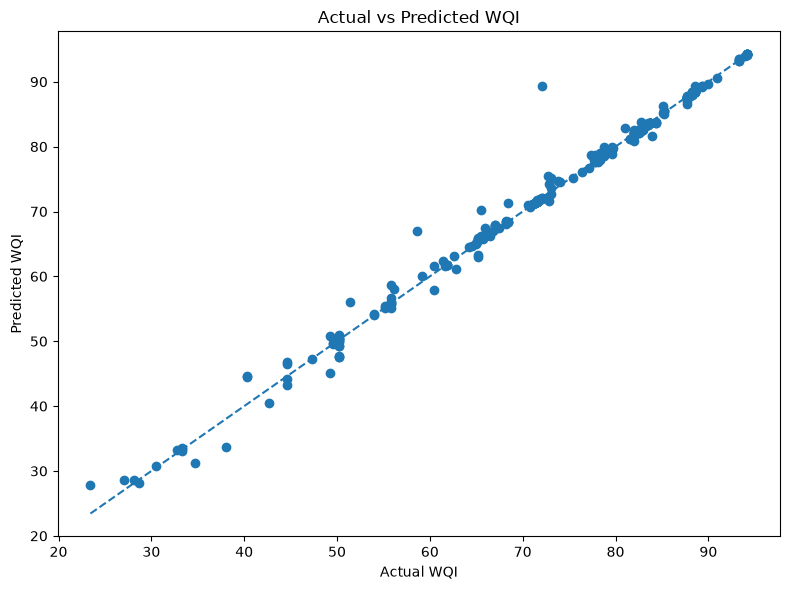


FEATURE IMPORTANCE
                         Feature  Importance
  TOTAL COLIFORM (MPN/100ml)Mean    0.546021
                     D.O. (mg/l)    0.286621
                              PH    0.110310
                   B.O.D. (mg/l)    0.055952
         CONDUCTIVITY (µmhos/cm)    0.000860
NITRATENAN N+ NITRITENANN (mg/l)    0.000156
                            Temp    0.000080


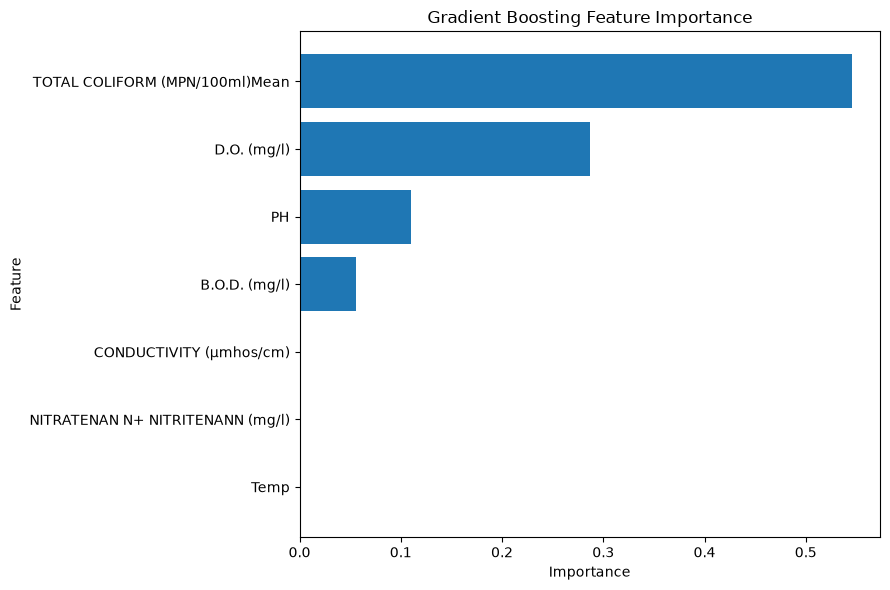


SHAP FEATURE IMPORTANCE


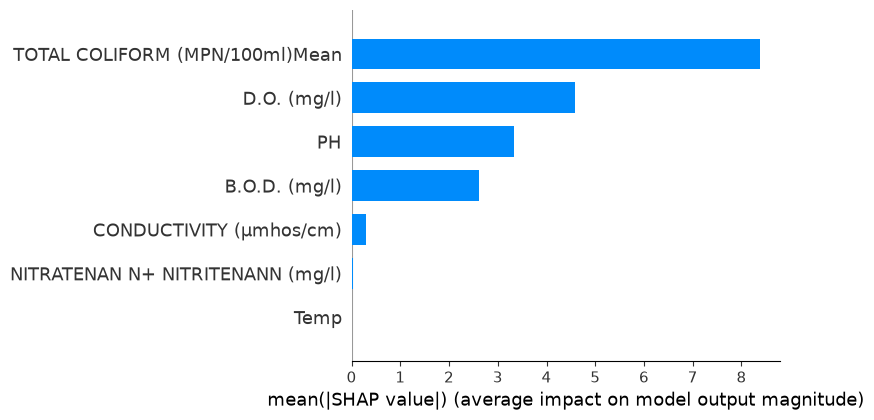

In [4]:
# ============================================================
# AI WATER QUALITY PREDICTION MODEL
# ============================================================

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# FEATURES AND TARGET
# ============================================================

features = [
    "Temp",
    "D.O. (mg/l)",
    "PH",
    "CONDUCTIVITY (µmhos/cm)",
    "B.O.D. (mg/l)",
    "NITRATENAN N+ NITRITENANN (mg/l)",
    "TOTAL COLIFORM (MPN/100ml)Mean"
]

X = wqi_df[features]
y = wqi_df["WQI"]


# ============================================================
# TRAIN / TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))


# ============================================================
# MODEL COMPARISON
# ============================================================

models = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    )
}

results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2 Score": r2_score(y_test, predictions)
    })


results_df = pd.DataFrame(results)

print("\n" + "=" * 60)
print("MODEL COMPARISON")
print("=" * 60)

print(
    results_df
    .sort_values("R2 Score", ascending=False)
    .to_string(index=False)
)


# ============================================================
# HYPERPARAMETER TUNING
# ============================================================

gb = GradientBoostingRegressor(random_state=42)

param_grid = {
    "n_estimators": [50, 100, 150],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_depth": [2, 3, 4],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

grid_search = GridSearchCV(
    gb,
    param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("\n" + "=" * 60)
print("BEST HYPERPARAMETERS")
print("=" * 60)

print(grid_search.best_params_)

print("\nBest Cross-Validation R2:")
print(grid_search.best_score_)


# ============================================================
# FINAL TUNED MODEL
# ============================================================

best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\n" + "=" * 60)
print("FINAL TUNED GRADIENT BOOSTING MODEL")
print("=" * 60)

print("MAE  :", mae)
print("RMSE :", rmse)
print("R²   :", r2)


# ============================================================
# ACTUAL VS PREDICTED
# ============================================================

comparison = pd.DataFrame({
    "Actual WQI": y_test.values,
    "Predicted WQI": y_pred
})

print("\n" + "=" * 60)
print("ACTUAL VS PREDICTED")
print("=" * 60)

print(comparison.head(20).to_string(index=False))


# ============================================================
# ACTUAL VS PREDICTED PLOT
# ============================================================

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual WQI")
plt.ylabel("Predicted WQI")
plt.title("Actual vs Predicted WQI")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.tight_layout()
plt.show()


# ============================================================
# FEATURE IMPORTANCE
# ============================================================

importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": best_model.feature_importances_
})

importance = importance.sort_values(
    "Importance",
    ascending=False
)

print("\n" + "=" * 60)
print("FEATURE IMPORTANCE")
print("=" * 60)

print(importance.to_string(index=False))


# ============================================================
# FEATURE IMPORTANCE PLOT
# ============================================================

plt.figure(figsize=(9, 6))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Gradient Boosting Feature Importance")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()


# ============================================================
# SHAP ANALYSIS
# ============================================================

import shap

explainer = shap.TreeExplainer(best_model)

shap_values = explainer.shap_values(X_test)

print("\n" + "=" * 60)
print("SHAP FEATURE IMPORTANCE")
print("=" * 60)

shap.summary_plot(
    shap_values,
    X_test,
    plot_type="bar"
)

In [5]:
import joblib

joblib.dump(best_model, "../model/wqi_model.pkl")
joblib.dump(features, "../model/features.pkl")

print("Model saved successfully!")

Model saved successfully!
